# ENGE707 Kaggle Competition: Group-Aware ResNet18 Baseline

## Controlled Retraining Experiment

This notebook retrains the unchanged ResNet18 baseline using the group-aware 80/20 split created in Notebook 8.

The architecture, ImageNet weights, preprocessing, augmentation, optimizer, learning rates, batch size, two-stage schedule, maximum epochs, time guard, and checkpoint rule are identical to the original ResNet18 experiment. **The only experimental change is the split.**

The notebook will:

1. load and verify the group-aware split;
2. confirm that connected near-duplicate groups do not cross subsets;
3. train the classifier head and then fine-tune the full network;
4. save the best group-aware checkpoint under a new filename;
5. generate learning curves and report evidence; and
6. compare the group-aware validation accuracy with the original 99.6544% result.

The original checkpoint and Kaggle submission are not overwritten. Kaggle test images are not loaded or used.

## 1. Import the Required Libraries

The imports support file handling, reproducibility, image processing, PyTorch transfer learning, evidence tables, plots, and result packaging. No Kaggle test-prediction library is needed in this training notebook.

In [1]:
# Imports the libraries used for ResNet18 training and saved evidence
from pathlib import Path
from contextlib import nullcontext
from itertools import chain
from zipfile import ZipFile, ZIP_DEFLATED
import json
import random
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from PIL import Image, ImageOps

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights
from torchvision.transforms import InterpolationMode

from IPython.display import FileLink, Markdown, display

## 2. Set Reproducibility Values

A fixed seed makes the data-loader order and other random operations repeatable. Exact GPU results can still vary slightly because of low-level GPU operations.

In [2]:
# Sets random seeds to make the experiment more repeatable
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Random seed:", RANDOM_SEED)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", __import__("torchvision").__version__)

Random seed: 42
PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128


## 3. Configure the Controlled Experiment

Training is enabled for the Kaggle run. Every training setting matches the original ResNet18 baseline so that any validation difference can be attributed to the group-aware split rather than a changed model or hyperparameter.

In [3]:
# Sets the training stages learning rates and stopping limits
RUN_TRAINING = True

HEAD_ONLY_EPOCHS = 2
FINE_TUNING_EPOCHS = 8
MAXIMUM_EPOCHS = HEAD_ONLY_EPOCHS + FINE_TUNING_EPOCHS

HEAD_ONLY_LEARNING_RATE = 1e-3
EARLY_BACKBONE_LEARNING_RATE = 1e-5
FINAL_BLOCK_LEARNING_RATE = 5e-5
CLASSIFIER_LEARNING_RATE = 2e-4

WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05
EARLY_STOPPING_PATIENCE = 3
SCHEDULER_PATIENCE = 1
SCHEDULER_FACTOR = 0.2

KAGGLE_BATCH_SIZE = 128
TRAINING_TIME_GUARD_MINUTES = 100
ASSIGNMENT_TIME_LIMIT_MINUTES = 120

print("Training enabled:", RUN_TRAINING)
print("Maximum epochs:", MAXIMUM_EPOCHS)
print("Time guard:", TRAINING_TIME_GUARD_MINUTES, "minutes")
print("Assignment limit:", ASSIGNMENT_TIME_LIMIT_MINUTES, "minutes")

Training enabled: True
Maximum epochs: 10
Time guard: 100 minutes
Assignment limit: 120 minutes


## 4. Prepare Local or Kaggle File Access

Kaggle inputs are read-only. Attach:

- the private competition dataset containing the training images;
- the project-artifact dataset containing `preprocessing_config.json`;
- the group-aware split dataset containing `train_split_group_aware.csv` and `validation_split_group_aware.csv`; and
- the official `resnet18-f37072fd.pth` ImageNet weights when Internet is disabled.

Only training images are located. Test images and `sample_submission.csv` are not needed in this experiment.

In [4]:
# Finds the required inputs when running locally or on Kaggle
RUNNING_ON_KAGGLE = Path("/kaggle/input").exists()


def find_kaggle_input_file(
    filename,
    required=True,
    preferred_text=None,
):
    """Find one unambiguous named file among Kaggle inputs."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if preferred_text:
        preferred = [
            path for path in matches
            if preferred_text.lower() in str(path).lower()
        ]
        if preferred:
            matches = preferred

    if len(matches) == 1:
        return matches[0]
    if not required and len(matches) == 0:
        return None

    match_text = "\n".join(str(path) for path in matches)
    raise RuntimeError(
        f"Expected exactly one {filename}, found {len(matches)}.\n"
        f"Matches:\n{match_text}"
    )


def find_kaggle_image_directory(filename, split_name):
    """Find one image folder containing a known file."""
    matches = sorted(Path("/kaggle/input").rglob(filename))
    matching_split = [
        path for path in matches
        if split_name.lower() in {
            part.lower() for part in path.parent.parts
        }
    ]
    directories = sorted({path.parent for path in matching_split})
    if len(directories) != 1:
        directory_text = "\n".join(str(path) for path in directories)
        raise RuntimeError(
            f"Expected one {split_name} image directory, found "
            f"{len(directories)}.\n{directory_text}"
        )
    return directories[0]


if RUNNING_ON_KAGGLE:
    kaggle_project_root = Path("/kaggle/working")

    train_split_source = find_kaggle_input_file(
        "train_split_group_aware.csv",
        required=False,
    )
    validation_split_source = find_kaggle_input_file(
        "validation_split_group_aware.csv",
        required=False,
    )
    config_source = find_kaggle_input_file(
        "preprocessing_config.json",
        preferred_text="facial-feature-project-artifacts",
    )

    if train_split_source is None or validation_split_source is None:
        split_archive = find_kaggle_input_file(
            "group_aware_split_results.zip"
        )
        extracted_split_dir = (
            kaggle_project_root / "group_aware_split_input"
        )
        extracted_split_dir.mkdir(parents=True, exist_ok=True)

        with ZipFile(split_archive) as archive:
            for split_filename in [
                "train_split_group_aware.csv",
                "validation_split_group_aware.csv",
            ]:
                archive.extract(split_filename, extracted_split_dir)

        train_split_source = (
            extracted_split_dir / "train_split_group_aware.csv"
        )
        validation_split_source = (
            extracted_split_dir
            / "validation_split_group_aware.csv"
        )
        print("Group-aware splits extracted from:", split_archive)

    split_probe = pd.read_csv(
        train_split_source,
        dtype={"filename": "string"},
        nrows=1,
    )
    train_probe_filename = split_probe.iloc[0]["filename"]
    kaggle_train_images = find_kaggle_image_directory(
        train_probe_filename,
        "train",
    )

    local_split_dir = kaggle_project_root / "splits" / "group_aware"
    local_config_dir = (
        kaggle_project_root / "outputs" / "preprocessing"
    )
    local_train_parent = kaggle_project_root / "data" / "train"

    local_split_dir.mkdir(parents=True, exist_ok=True)
    local_config_dir.mkdir(parents=True, exist_ok=True)
    local_train_parent.mkdir(parents=True, exist_ok=True)

    shutil.copy2(
        train_split_source,
        local_split_dir / "train_split_group_aware.csv",
    )
    shutil.copy2(
        validation_split_source,
        local_split_dir / "validation_split_group_aware.csv",
    )
    shutil.copy2(
        config_source,
        local_config_dir / "preprocessing_config.json",
    )

    train_link = local_train_parent / "train"
    if not train_link.exists():
        train_link.symlink_to(
            kaggle_train_images,
            target_is_directory=True,
        )

    print("Kaggle environment detected.")
    print("Training images:", kaggle_train_images)
    print("Group-aware training split:", train_split_source)
    print("Group-aware validation split:", validation_split_source)
else:
    print("Local project environment detected.")

Kaggle environment detected.
Training images: /kaggle/input/datasets/fatehbhular/ense707-facial-feature-competition-data/train/train
Group-aware training split: /kaggle/input/datasets/fatehbhular/facial-feature-group-split-training/train_split_group_aware.csv
Group-aware validation split: /kaggle/input/datasets/fatehbhular/facial-feature-group-split-training/validation_split_group_aware.csv


## 5. Locate Project Files and Separate Output Folders

Every checkpoint and evidence filename is separate from the original baseline. This preserves the current best model and makes the experiment fully reversible.

In [5]:
# Finds the project paths and prepares separate output folders
possible_project_roots = [Path.cwd(), Path.cwd().parent]

PROJECT_ROOT = next(
    (
        folder for folder in possible_project_roots
        if (
            folder
            / "splits"
            / "group_aware"
            / "train_split_group_aware.csv"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "The project folder containing the group-aware split "
        "could not be found."
    )

TRAIN_IMAGE_DIR = PROJECT_ROOT / "data" / "train" / "train"
TRAIN_SPLIT_PATH = (
    PROJECT_ROOT
    / "splits"
    / "group_aware"
    / "train_split_group_aware.csv"
)
VALIDATION_SPLIT_PATH = (
    PROJECT_ROOT
    / "splits"
    / "group_aware"
    / "validation_split_group_aware.csv"
)
PREPROCESSING_CONFIG_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "preprocessing"
    / "preprocessing_config.json"
)

MODEL_OUTPUT_DIR = (
    PROJECT_ROOT / "outputs" / "models" / "group_aware_baseline"
)
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
CHECKPOINT_DIR = PROJECT_ROOT / "models" / "group_aware_baseline"

BEST_MODEL_PATH = CHECKPOINT_DIR / "resnet18_group_aware_best.pth"
TRAINING_HISTORY_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_training_history.csv"
)
TRAINING_SUMMARY_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_training_summary.json"
)
PIPELINE_CONFIG_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_pipeline_config.json"
)
ARCHITECTURE_TABLE_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_architecture.csv"
)
HYPERPARAMETER_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_hyperparameters.csv"
)
PARAMETER_SUMMARY_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_parameter_summary.csv"
)
TRAINING_STAGES_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_training_stages.csv"
)
GENERALISATION_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_generalisation_strategies.csv"
)
PIPELINE_CHECKS_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_pipeline_checks.csv"
)
BEHAVIOUR_EVIDENCE_PATH = (
    MODEL_OUTPUT_DIR / "group_aware_resnet18_behaviour_evidence.csv"
)

ARCHITECTURE_FIGURE_PATH = (
    FIGURE_DIR / "figure_26_group_aware_resnet18_architecture.png"
)
LEARNING_CURVES_PATH = (
    FIGURE_DIR / "figure_27_group_aware_resnet18_learning_curves.png"
)

MODEL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [
    TRAIN_IMAGE_DIR,
    TRAIN_SPLIT_PATH,
    VALIDATION_SPLIT_PATH,
    PREPROCESSING_CONFIG_PATH,
]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        "The following required paths are missing:\n"
        + "\n".join(str(path) for path in missing_paths)
    )

print("Project folder:", PROJECT_ROOT)
print("Checkpoint:", BEST_MODEL_PATH)
print("Evidence folder:", MODEL_OUTPUT_DIR)
print("Figure folder:", FIGURE_DIR)

Project folder: /kaggle/working
Checkpoint: /kaggle/working/models/group_aware_baseline/resnet18_group_aware_best.pth
Evidence folder: /kaggle/working/outputs/models/group_aware_baseline
Figure folder: /kaggle/working/outputs/figures


## 6. Load the Configuration and Group-Aware Splits

The official class mapping and preprocessing configuration remain unchanged. Only the membership of the training and validation subsets differs from the original experiment.

In [6]:
# Loads the saved preprocessing settings and training and validation splits
with open(PREPROCESSING_CONFIG_PATH) as configuration_file:
    preprocessing_config = json.load(configuration_file)

training_split = pd.read_csv(
    TRAIN_SPLIT_PATH,
    dtype={
        "image_id": "string",
        "class": "string",
        "filename": "string",
        "group_id": "string",
    },
)

validation_split = pd.read_csv(
    VALIDATION_SPLIT_PATH,
    dtype={
        "image_id": "string",
        "class": "string",
        "filename": "string",
        "group_id": "string",
    },
)

IMAGE_SIZE = int(preprocessing_config["image_size"])
CLASS_NAMES = list(preprocessing_config["class_names"])
CLASS_TO_INDEX = dict(preprocessing_config["class_to_index"])
INDEX_TO_CLASS = {
    int(index): class_name
    for class_name, index in CLASS_TO_INDEX.items()
}
NUMBER_OF_CLASSES = len(CLASS_NAMES)

print("Training images:", f"{len(training_split):,}")
print("Validation images:", f"{len(validation_split):,}")
print("Image size:", f"{IMAGE_SIZE} × {IMAGE_SIZE}")
print("Classes:", CLASS_NAMES)

Training images: 50,928
Validation images: 12,732
Image size: 224 × 224
Classes: ['CatEye', 'DogEye', 'CatFace', 'DogFace', 'CatMouth', 'DogMouth', 'CatNose', 'DogNose']


## 7. Verify the Group-Aware Split and Prevent Leakage

These checks confirm the expected image counts, official label mapping, and complete separation of image IDs and connected perceptual groups.

In [7]:
# Checks that the saved subsets do not share image identifiers or groups
shared_image_ids = (
    set(training_split["image_id"])
    & set(validation_split["image_id"])
)
shared_group_ids = (
    set(training_split["group_id"])
    & set(validation_split["group_id"])
)

expected_classes = set(CLASS_NAMES)
encoded_labels_are_valid = (
    training_split["label_index"].between(
        0, NUMBER_OF_CLASSES - 1
    ).all()
    and validation_split["label_index"].between(
        0, NUMBER_OF_CLASSES - 1
    ).all()
)

encoded_labels_match_classes = (
    (
        training_split["label_index"]
        == training_split["class"].map(CLASS_TO_INDEX)
    ).all()
    and (
        validation_split["label_index"]
        == validation_split["class"].map(CLASS_TO_INDEX)
    ).all()
)

split_checks = pd.DataFrame(
    {
        "check": [
            "Training subset contains 50,928 images",
            "Validation subset contains 12,732 images",
            "No image IDs cross between subsets",
            "No connected perceptual groups cross between subsets",
            "All classes appear in training",
            "All classes appear in validation",
            "Encoded labels are between 0 and 7",
            "Encoded labels match the official class mapping",
        ],
        "result": [
            len(training_split) == 50928,
            len(validation_split) == 12732,
            len(shared_image_ids) == 0,
            len(shared_group_ids) == 0,
            set(training_split["class"]) == expected_classes,
            set(validation_split["class"]) == expected_classes,
            encoded_labels_are_valid,
            encoded_labels_match_classes,
        ],
        "expected": [True] * 8,
    }
)

display(split_checks)
assert split_checks["result"].all()
print("All group-aware split and leakage checks passed.")

,check,result,expected
0,"Training subset contains 50,928 images",True,True
1,"Validation subset contains 12,732 images",True,True
2,No image IDs cross between subsets,True,True
3,No connected perceptual groups cross between s...,True,True
4,All classes appear in training,True,True
5,All classes appear in validation,True,True
6,Encoded labels are between 0 and 7,True,True
7,Encoded labels match the official class mapping,True,True


All group-aware split and leakage checks passed.


## 8. Select the Device and Efficient Batch Size

Kaggle GPU training uses a larger batch than the earlier preparation notebook. This improves GPU use without changing the images, labels, preprocessing, or validation split.

In [8]:
# Chooses the device and an appropriate batch size for the available hardware
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

BATCH_SIZE = (
    KAGGLE_BATCH_SIZE
    if DEVICE.type == "cuda"
    else int(preprocessing_config["batch_size"])
)

NUM_WORKERS = (
    4
    if RUNNING_ON_KAGGLE
    else int(preprocessing_config["num_workers"])
)
PIN_MEMORY = DEVICE.type == "cuda"
USE_MIXED_PRECISION = DEVICE.type == "cuda"

if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("Selected device:", DEVICE)
print("CUDA devices:", torch.cuda.device_count())
print("Batch size:", BATCH_SIZE)
print("Data-loader workers:", NUM_WORKERS)
print("Mixed precision:", USE_MIXED_PRECISION)

Selected device: cuda
CUDA devices: 2
Batch size: 128
Data-loader workers: 4
Mixed precision: True


## 9. Recreate the Image Transformations

Training images receive the same small random changes defined in Notebook 2. Validation images receive deterministic square padding, resizing, tensor conversion, and ImageNet normalisation only.

In [9]:
# Recreates training changes and fixed validation preprocessing
class SquarePad:
    """Add equal padding around the shorter sides of an image."""

    def __init__(self, fill=(0, 0, 0)):
        self.fill = fill

    def __call__(self, image):
        width, height = image.size
        largest_side = max(width, height)

        horizontal_padding = largest_side - width
        vertical_padding = largest_side - height

        left_padding = horizontal_padding // 2
        right_padding = horizontal_padding - left_padding
        top_padding = vertical_padding // 2
        bottom_padding = vertical_padding - top_padding

        return ImageOps.expand(
            image,
            border=(
                left_padding,
                top_padding,
                right_padding,
                bottom_padding,
            ),
            fill=self.fill,
        )


IMAGENET_MEAN = preprocessing_config["normalisation_mean"]
IMAGENET_STD = preprocessing_config["normalisation_std"]
augmentation_config = preprocessing_config["training_augmentation"]

training_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.RandomHorizontalFlip(
            p=augmentation_config[
                "horizontal_flip_probability"
            ]
        ),
        transforms.RandomRotation(
            degrees=augmentation_config[
                "maximum_rotation_degrees"
            ],
            interpolation=InterpolationMode.BILINEAR,
            fill=(0, 0, 0),
        ),
        transforms.ColorJitter(
            brightness=augmentation_config["brightness_change"],
            contrast=augmentation_config["contrast_change"],
            saturation=augmentation_config["saturation_change"],
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

evaluation_transform = transforms.Compose(
    [
        SquarePad(),
        transforms.Resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=InterpolationMode.BILINEAR,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ]
)

print("Training transform:")
print(training_transform)
print("\nValidation transform:")
print(evaluation_transform)

Training transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=bilinear, expand=False, fill=(0, 0, 0))
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.9, 1.1), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Validation transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 10. Create Dataset Objects and Data Loaders

The training loader shuffles the group-aware training subset. The validation loader preserves order and receives no random augmentation. No test loader is created.

In [10]:
# Creates dataset objects and batch loaders for the saved subsets
class FacialFeatureDataset(Dataset):
    """Load facial-feature images for PyTorch."""

    def __init__(
        self,
        dataframe,
        image_directory,
        transform,
        include_labels=True,
    ):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self.transform = transform
        self.include_labels = include_labels

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        image_path = self.image_directory / row["filename"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        item = {
            "image": image,
            "image_id": row["image_id"],
        }

        if self.include_labels:
            item["label"] = int(row["label_index"])
            item["class_name"] = row["class"]

        return item


training_dataset = FacialFeatureDataset(
    training_split,
    TRAIN_IMAGE_DIR,
    training_transform,
    include_labels=True,
)
validation_dataset = FacialFeatureDataset(
    validation_split,
    TRAIN_IMAGE_DIR,
    evaluation_transform,
    include_labels=True,
)

loader_options = {}
if NUM_WORKERS > 0:
    loader_options = {
        "persistent_workers": True,
        "prefetch_factor": 2,
    }

loader_generator = torch.Generator()
loader_generator.manual_seed(RANDOM_SEED)

training_loader = DataLoader(
    training_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=loader_generator,
    **loader_options,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    **loader_options,
)

print("Training batches:", len(training_loader))
print("Validation batches:", len(validation_loader))
print("Training dataset:", len(training_dataset))
print("Validation dataset:", len(validation_dataset))

Training batches: 398
Validation batches: 100
Training dataset: 50928
Validation dataset: 12732


## 11. Load ResNet18 and Replace Its Classifier

ImageNet-pretrained weights are used during the real Kaggle training run. When Internet is disabled, attach the official resnet18-f37072fd.pth weights file as a private Kaggle input.

In preparation mode, random weights are sufficient for checking the architecture and code without downloading anything. They must not be used for the actual experiment.

In [11]:
# Builds ResNet18 with pretrained weights and an eight class output layer
def build_resnet18(number_of_classes, load_pretrained):
    """Build ResNet18 and record where its initial weights came from."""
    weight_source = "not loaded - preparation mode"

    if load_pretrained:
        weights = ResNet18_Weights.DEFAULT
        weight_filename = Path(weights.url).name
        cache_path = (
            Path(torch.hub.get_dir())
            / "checkpoints"
            / weight_filename
        )

        attached_path = None
        if RUNNING_ON_KAGGLE:
            attached_path = find_kaggle_input_file(
                weight_filename,
                required=False,
            )

        if attached_path is not None:
            model = models.resnet18(weights=None)
            # Reads the saved checkpoint so training does not need to be repeated
            state_dict = torch.load(
                attached_path,
                map_location="cpu",
                weights_only=True,
            )
            # Copies the saved weights into the matching model architecture
            model.load_state_dict(state_dict)
            weight_source = f"attached Kaggle input: {attached_path}"
        elif cache_path.exists():
            model = models.resnet18(weights=None)
            # Reads the saved checkpoint so training does not need to be repeated
            state_dict = torch.load(
                cache_path,
                map_location="cpu",
                weights_only=True,
            )
            # Copies the saved weights into the matching model architecture
            model.load_state_dict(state_dict)
            weight_source = f"PyTorch cache: {cache_path}"
        else:
            try:
                model = models.resnet18(weights=weights)
                weight_source = "downloaded torchvision ImageNet weights"
            except Exception as error:
                raise RuntimeError(
                    "Pretrained ResNet18 weights could not be loaded. "
                    "Attach resnet18-f37072fd.pth or enable Internet."
                ) from error
    else:
        model = models.resnet18(weights=None)

    original_features = model.fc.in_features
    model.fc = nn.Linear(original_features, number_of_classes)

    return model, weight_source


resnet18_model, PRETRAINED_WEIGHT_SOURCE = build_resnet18(
    NUMBER_OF_CLASSES,
    load_pretrained=RUN_TRAINING,
)

print("Pretrained-weight source:", PRETRAINED_WEIGHT_SOURCE)
print("Replacement classifier:", resnet18_model.fc)

Pretrained-weight source: attached Kaggle input: /kaggle/input/datasets/fatehbhular/facial-feature-project-artifacts/resnet18-f37072fd.pth
Replacement classifier: Linear(in_features=512, out_features=8, bias=True)


## 12. Explain and Save the Architecture

ResNet18 contains an initial convolutional stem followed by four groups of residual blocks. The number of feature channels increases while spatial size decreases. Global average pooling converts the final feature maps into 512 values, and the replacement linear layer produces eight class scores.

,component,output_description,purpose
0,Input,3 × 224 × 224 RGB tensor,Normalised facial-feature image
1,Convolutional stem,64 channels,"Learn basic edges, colours, and textures"
2,Residual layer 1,64 channels; 2 residual blocks,Preserve and combine low-level features
3,Residual layer 2,128 channels; 2 residual blocks,Learn more detailed patterns
4,Residual layer 3,256 channels; 2 residual blocks,Learn higher-level facial-part structure
5,Residual layer 4,512 channels; 2 residual blocks,Adapt high-level features to this dataset
6,Adaptive average pooling,512 features,Summarise each final feature map
7,Replacement classifier,8 unnormalised class scores,Predict one competition class


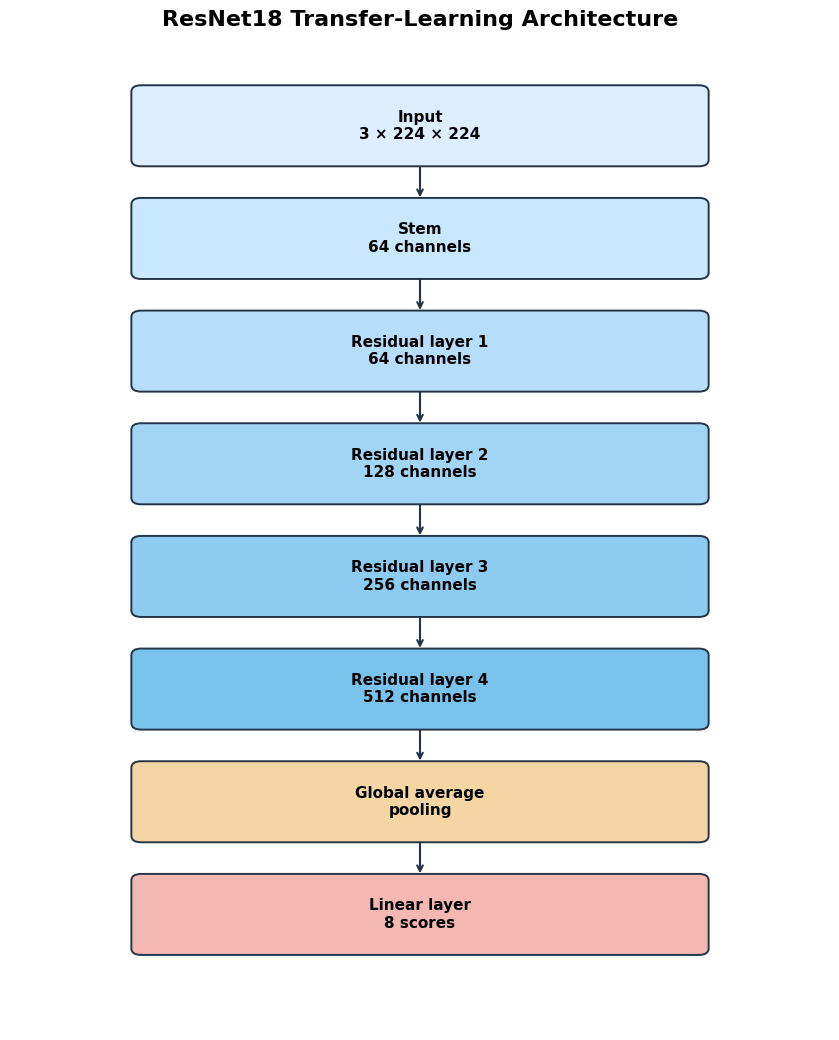

Architecture table: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_architecture.csv
Architecture figure: /kaggle/working/outputs/figures/figure_26_group_aware_resnet18_architecture.png


In [12]:
# Records the architecture and saves a diagram for the report
architecture_rows = [
    {
        "component": "Input",
        "output_description": "3 × 224 × 224 RGB tensor",
        "purpose": "Normalised facial-feature image",
    },
    {
        "component": "Convolutional stem",
        "output_description": "64 channels",
        "purpose": "Learn basic edges, colours, and textures",
    },
    {
        "component": "Residual layer 1",
        "output_description": "64 channels; 2 residual blocks",
        "purpose": "Preserve and combine low-level features",
    },
    {
        "component": "Residual layer 2",
        "output_description": "128 channels; 2 residual blocks",
        "purpose": "Learn more detailed patterns",
    },
    {
        "component": "Residual layer 3",
        "output_description": "256 channels; 2 residual blocks",
        "purpose": "Learn higher-level facial-part structure",
    },
    {
        "component": "Residual layer 4",
        "output_description": "512 channels; 2 residual blocks",
        "purpose": "Adapt high-level features to this dataset",
    },
    {
        "component": "Adaptive average pooling",
        "output_description": "512 features",
        "purpose": "Summarise each final feature map",
    },
    {
        "component": "Replacement classifier",
        "output_description": "8 unnormalised class scores",
        "purpose": "Predict one competition class",
    },
]

architecture_table = pd.DataFrame(architecture_rows)
# Saves the table as a CSV file for later notebooks or report evidence
architecture_table.to_csv(ARCHITECTURE_TABLE_PATH, index=False)
display(architecture_table)

diagram_labels = [
    ("Input\n3 × 224 × 224", "#DCEEFF"),
    ("Stem\n64 channels", "#C9E7FF"),
    ("Residual layer 1\n64 channels", "#B6DEFA"),
    ("Residual layer 2\n128 channels", "#A2D5F5"),
    ("Residual layer 3\n256 channels", "#8DCCF0"),
    ("Residual layer 4\n512 channels", "#78C2EB"),
    ("Global average\npooling", "#F3D6A4"),
    ("Linear layer\n8 scores", "#F5B7B1"),
]

fig, ax = plt.subplots(figsize=(8.5, 10.5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 18)
ax.axis("off")

box_width = 6.8
box_height = 1.25
x_position = 1.6
y_positions = np.linspace(16, 1.5, len(diagram_labels))

for index, ((label, colour), y_position) in enumerate(
    zip(diagram_labels, y_positions)
):
    box = FancyBboxPatch(
        (x_position, y_position),
        box_width,
        box_height,
        boxstyle="round,pad=0.12",
        linewidth=1.4,
        edgecolor="#243447",
        facecolor=colour,
    )
    ax.add_patch(box)
    ax.text(
        x_position + box_width / 2,
        y_position + box_height / 2,
        label,
        ha="center",
        va="center",
        fontsize=11,
        weight="bold",
    )

    if index < len(diagram_labels) - 1:
        next_y = y_positions[index + 1] + box_height
        ax.annotate(
            "",
            xy=(5, next_y + 0.08),
            xytext=(5, y_position - 0.08),
            arrowprops={
                "arrowstyle": "->",
                "linewidth": 1.5,
                "color": "#243447",
            },
        )

ax.set_title(
    "ResNet18 Transfer-Learning Architecture",
    fontsize=16,
    weight="bold",
    pad=18,
)
fig.tight_layout()
# Saves the figure so it can be included in the report
fig.savefig(
    ARCHITECTURE_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Architecture table:", ARCHITECTURE_TABLE_PATH)
print("Architecture figure:", ARCHITECTURE_FIGURE_PATH)

## 13. Record Parameter Counts and Training Stages

Stage 1 updates only the new classifier. Stage 2 updates the complete network, but early layers receive the smallest learning rate because their general visual features require less change.

In [13]:
# Counts model parameters and records the planned training stages
def number_of_parameters(parameters):
    return sum(parameter.numel() for parameter in parameters)


total_parameters = number_of_parameters(
    resnet18_model.parameters()
)
classifier_parameters = number_of_parameters(
    resnet18_model.fc.parameters()
)
backbone_parameters = total_parameters - classifier_parameters

parameter_summary = pd.DataFrame(
    {
        "measure": [
            "Total parameters",
            "Backbone parameters",
            "Replacement-classifier parameters",
            "Trainable parameters in Stage 1",
            "Trainable parameters in Stage 2",
        ],
        "parameters": [
            total_parameters,
            backbone_parameters,
            classifier_parameters,
            classifier_parameters,
            total_parameters,
        ],
        "percentage_of_model": [
            100.0,
            backbone_parameters / total_parameters * 100,
            classifier_parameters / total_parameters * 100,
            classifier_parameters / total_parameters * 100,
            100.0,
        ],
    }
)
# Saves the table as a CSV file for later notebooks or report evidence
parameter_summary.to_csv(PARAMETER_SUMMARY_PATH, index=False)

training_stages = pd.DataFrame(
    [
        {
            "stage": "Stage 1 - classifier only",
            "maximum_epochs": HEAD_ONLY_EPOCHS,
            "trainable_components": "Replacement classifier",
            "early_backbone_lr": 0.0,
            "final_block_lr": 0.0,
            "classifier_lr": HEAD_ONLY_LEARNING_RATE,
        },
        {
            "stage": "Stage 2 - full fine-tuning",
            "maximum_epochs": FINE_TUNING_EPOCHS,
            "trainable_components": "Complete ResNet18",
            "early_backbone_lr": EARLY_BACKBONE_LEARNING_RATE,
            "final_block_lr": FINAL_BLOCK_LEARNING_RATE,
            "classifier_lr": CLASSIFIER_LEARNING_RATE,
        },
    ]
)
# Saves the table as a CSV file for later notebooks or report evidence
training_stages.to_csv(TRAINING_STAGES_PATH, index=False)

display(parameter_summary.round(2))
display(training_stages)
print("Parameter summary:", PARAMETER_SUMMARY_PATH)
print("Training stages:", TRAINING_STAGES_PATH)

,measure,parameters,percentage_of_model
0,Total parameters,11180616,100.00
1,Backbone parameters,11176512,99.96
2,Replacement-classifier parameters,4104,0.04
3,Trainable parameters in Stage 1,4104,0.04
4,Trainable parameters in Stage 2,11180616,100.00


,stage,maximum_epochs,trainable_components,early_backbone_lr,final_block_lr,classifier_lr
0,Stage 1 - classifier only,2,Replacement classifier,0.00000,0.00000,0.0010
1,Stage 2 - full fine-tuning,8,Complete ResNet18,0.00001,0.00005,0.0002


Parameter summary: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_parameter_summary.csv
Training stages: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_training_stages.csv


## 14. Record and Justify the Hyperparameters

The settings balance model quality, generalisation, and the two-hour runtime limit. Unweighted cross-entropy is used because Kaggle measures overall accuracy and the class imbalance is moderate rather than extreme.

In [14]:
# Records the chosen training settings and their reasons
hyperparameters = pd.DataFrame(
    [
        ("Architecture", "ResNet18", "Strong efficient transfer-learning baseline"),
        ("Initial weights", "ImageNet", "Reuse general visual features"),
        ("Input size", IMAGE_SIZE, "Required by the selected pretrained setup"),
        ("Batch size", BATCH_SIZE, "Improve GPU throughput while fitting memory"),
        ("Stage 1 epochs", HEAD_ONLY_EPOCHS, "Fit the new classifier first"),
        ("Stage 2 epochs", FINE_TUNING_EPOCHS, "Adapt pretrained features"),
        ("Stage 1 classifier LR", HEAD_ONLY_LEARNING_RATE, "Rapidly fit the new layer"),
        ("Early-backbone LR", EARLY_BACKBONE_LEARNING_RATE, "Protect general features"),
        ("Final-block LR", FINAL_BLOCK_LEARNING_RATE, "Adapt high-level features"),
        ("Fine-tuning classifier LR", CLASSIFIER_LEARNING_RATE, "Continue adapting the new layer"),
        ("Optimiser", "AdamW", "Adaptive updates with decoupled weight decay"),
        ("Weight decay", WEIGHT_DECAY, "Reduce excessively large weights"),
        ("Loss", "CrossEntropyLoss", "Suitable for single-label multiclass classification"),
        ("Label smoothing", LABEL_SMOOTHING, "Reduce overconfident fitting"),
        ("Scheduler", "ReduceLROnPlateau", "Lower learning rates when validation loss stalls"),
        ("Scheduler factor", SCHEDULER_FACTOR, "Make a meaningful LR reduction"),
        ("Early-stopping patience", EARLY_STOPPING_PATIENCE, "Stop sustained non-improvement"),
        ("Time guard (minutes)", TRAINING_TIME_GUARD_MINUTES, "Leave time before the two-hour limit"),
        ("Random seed", RANDOM_SEED, "Support reproducibility"),
    ],
    columns=["hyperparameter", "value", "reason"],
)
# Saves the table as a CSV file for later notebooks or report evidence
hyperparameters.to_csv(HYPERPARAMETER_PATH, index=False)
display(hyperparameters)
print("Hyperparameter evidence:", HYPERPARAMETER_PATH)

,hyperparameter,value,reason
0,Architecture,ResNet18,Strong efficient transfer-learning baseline
1,Initial weights,ImageNet,Reuse general visual features
2,Input size,224,Required by the selected pretrained setup
3,Batch size,128,Improve GPU throughput while fitting memory
4,Stage 1 epochs,2,Fit the new classifier first
5,Stage 2 epochs,8,Adapt pretrained features
6,Stage 1 classifier LR,0.001,Rapidly fit the new layer
7,Early-backbone LR,0.00001,Protect general features
8,Final-block LR,0.00005,Adapt high-level features
9,Fine-tuning classifier LR,0.0002,Continue adapting the new layer


Hyperparameter evidence: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_hyperparameters.csv


## 15. Record Generalisation Strategies

This table connects each technique to the behaviour it is intended to control and provides direct evidence for the training-strategy section of the report.

In [15]:
# Records the techniques used to support generalisation
generalisation_strategies = pd.DataFrame(
    [
        (
            "Image augmentation",
            "Create small realistic changes in training images only",
        ),
        (
            "Transfer learning",
            "Start from useful visual features rather than random filters",
        ),
        (
            "Two-stage training",
            "Stabilise the classifier before changing pretrained layers",
        ),
        (
            "Discriminative learning rates",
            "Change early pretrained layers more carefully",
        ),
        (
            "AdamW weight decay",
            "Discourage unnecessarily large parameter values",
        ),
        (
            "Label smoothing",
            "Reduce overconfident predictions during training",
        ),
        (
            "Learning-rate scheduler",
            "Use smaller updates when validation loss stops improving",
        ),
        (
            "Early stopping",
            "Stop after sustained validation non-improvement",
        ),
        (
            "Best-checkpoint saving",
            "Keep the strongest validation model instead of the final epoch",
        ),
        (
            "Group-aware validation split",
            "Keep detected near-duplicate groups within one subset",
        ),
    ],
    columns=["strategy", "purpose"],
)
# Saves the table as a CSV file for later notebooks or report evidence
generalisation_strategies.to_csv(
    GENERALISATION_PATH,
    index=False,
)
display(generalisation_strategies)
print("Generalisation evidence:", GENERALISATION_PATH)

,strategy,purpose
0,Image augmentation,Create small realistic changes in training ima...
1,Transfer learning,Start from useful visual features rather than ...
2,Two-stage training,Stabilise the classifier before changing pretr...
3,Discriminative learning rates,Change early pretrained layers more carefully
4,AdamW weight decay,Discourage unnecessarily large parameter values
5,Label smoothing,Reduce overconfident predictions during training
6,Learning-rate scheduler,Use smaller updates when validation loss stops...
7,Early stopping,Stop after sustained validation non-improvement
8,Best-checkpoint saving,Keep the strongest validation model instead of...
9,Group-aware validation split,Keep detected near-duplicate groups within one...


Generalisation evidence: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_generalisation_strategies.csv


## 16. Verify the Complete Forward Pipeline

One labelled batch is sent through the untrained/pretrained architecture only to verify shapes. No backward pass or optimiser step occurs, so this check does not train the model.

In [16]:
# Checks that one image batch produces eight scores per image
example_batch = next(iter(training_loader))
example_images = example_batch["image"]
example_labels = example_batch["label"]

# Switches the model to evaluation behaviour for prediction
resnet18_model.eval()
# Disables gradient tracking because this step does not train the model
with torch.inference_mode():
    example_logits = resnet18_model(example_images)

forward_checks = pd.DataFrame(
    {
        "check": [
            "Input batch has four dimensions",
            "Input has three colour channels",
            "Images are 224 × 224",
            "One label exists per image",
            "Model returns one row per image",
            "Model returns eight class scores",
        ],
        "result": [
            example_images.ndim == 4,
            example_images.shape[1] == 3,
            tuple(example_images.shape[-2:])
            == (IMAGE_SIZE, IMAGE_SIZE),
            len(example_labels) == len(example_images),
            example_logits.shape[0] == len(example_images),
            example_logits.shape[1] == NUMBER_OF_CLASSES,
        ],
        "expected": [True] * 6,
    }
)

display(forward_checks)
assert forward_checks["result"].all()
print("Forward pipeline verified:", tuple(example_logits.shape))

,check,result,expected
0,Input batch has four dimensions,True,True
1,Input has three colour channels,True,True
2,Images are 224 × 224,True,True
3,One label exists per image,True,True
4,Model returns one row per image,True,True
5,Model returns eight class scores,True,True


Forward pipeline verified: (128, 8)


## 17. Save the Pipeline Configuration and Pre-Training Checks

These artifacts record the exact architecture, split, transformations, class order, and planned training settings before any weights are updated.

In [17]:
# Saves the pipeline configuration and checks required before training
pipeline_configuration = {
    "model_name": "resnet18",
    "experiment": "group_aware_baseline",
    "split_strategy": "stratified connected perceptual groups",
    "only_changed_variable": "training-validation split",
    "number_of_classes": NUMBER_OF_CLASSES,
    "class_names": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "random_seed": RANDOM_SEED,
    "pretrained_weights": "ImageNet ResNet18 default weights",
    "pretrained_weight_source": PRETRAINED_WEIGHT_SOURCE,
    "head_only_epochs": HEAD_ONLY_EPOCHS,
    "fine_tuning_epochs": FINE_TUNING_EPOCHS,
    "maximum_epochs": MAXIMUM_EPOCHS,
    "label_smoothing": LABEL_SMOOTHING,
    "weight_decay": WEIGHT_DECAY,
    "training_time_guard_minutes": TRAINING_TIME_GUARD_MINUTES,
    "training_images": len(training_dataset),
    "validation_images": len(validation_dataset),
    "training_augmentation": augmentation_config,
    "validation_random_augmentation": False,
}

with open(PIPELINE_CONFIG_PATH, "w") as config_file:
    json.dump(pipeline_configuration, config_file, indent=4)

pipeline_checks = pd.DataFrame(
    {
        "check": [
            "Eight official classes loaded",
            "Group-aware training subset loaded",
            "Group-aware validation subset loaded",
            "No shared image IDs",
            "No connected perceptual groups cross subsets",
            "Training and validation transforms differ",
            "Validation transform contains no random augmentation",
            "Forward pass returns eight scores",
            "Architecture evidence saved",
            "Hyperparameter evidence saved",
            "Training-stage evidence saved",
            "Generalisation evidence saved",
        ],
        "result": [
            NUMBER_OF_CLASSES == 8,
            len(training_dataset) == 50928,
            len(validation_dataset) == 12732,
            len(shared_image_ids) == 0,
            len(shared_group_ids) == 0,
            repr(training_transform) != repr(evaluation_transform),
            "Random" not in repr(evaluation_transform),
            example_logits.shape[1] == 8,
            ARCHITECTURE_TABLE_PATH.exists()
            and ARCHITECTURE_FIGURE_PATH.exists(),
            HYPERPARAMETER_PATH.exists(),
            TRAINING_STAGES_PATH.exists(),
            GENERALISATION_PATH.exists(),
        ],
        "expected": [True] * 12,
    }
)

# Saves the table as a CSV file for later notebooks or report evidence
pipeline_checks.to_csv(PIPELINE_CHECKS_PATH, index=False)
display(pipeline_checks)
assert pipeline_checks["result"].all()

print("Pipeline configuration:", PIPELINE_CONFIG_PATH)
print("Pipeline checks:", PIPELINE_CHECKS_PATH)

,check,result,expected
0,Eight official classes loaded,True,True
1,Group-aware training subset loaded,True,True
2,Group-aware validation subset loaded,True,True
3,No shared image IDs,True,True
4,No connected perceptual groups cross subsets,True,True
5,Training and validation transforms differ,True,True
6,Validation transform contains no random augmen...,True,True
7,Forward pass returns eight scores,True,True
8,Architecture evidence saved,True,True
9,Hyperparameter evidence saved,True,True


Pipeline configuration: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_pipeline_config.json
Pipeline checks: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_pipeline_checks.csv


# Part B: ResNet18 Training and Model Behaviour

The following sections update model weights only when RUN_TRAINING is True. The validation loader measures generalisation after every epoch, while the Kaggle test data remains unused.

## 18. Define Mixed-Precision Batch Handling

Mixed precision reduces GPU memory use and can accelerate training. Channels-last memory format and non-blocking transfers further improve CUDA throughput.

In [18]:
# Defines efficient handling of image batches on the chosen device
def mixed_precision_context(device, enabled):
    """Use CUDA automatic mixed precision when enabled."""
    if enabled and device.type == "cuda":
        return torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        )

    return nullcontext()


def prepare_batch_for_device(batch, device):
    """Move one labelled batch to the selected device."""
    non_blocking = device.type == "cuda"

    images = batch["image"].to(
        device,
        non_blocking=non_blocking,
    )
    labels = batch["label"].to(
        device,
        non_blocking=non_blocking,
    )

    if device.type == "cuda":
        images = images.contiguous(
            memory_format=torch.channels_last
        )

    return images, labels


def unwrap_model(model):
    """Return the underlying ResNet18 when DataParallel is used."""
    return model.module if isinstance(model, nn.DataParallel) else model

## 19. Configure Trainable Layers and Optimisers

During Stage 1, frozen batch-normalisation layers remain in evaluation mode so their stored statistics do not change. During Stage 2, all parameters and batch-normalisation layers are trainable.

In [19]:
# Freezes or unfreezes layers and sets the optimiser for each stage
def configure_training_stage(model, stage_name):
    """Freeze or unfreeze parameters for one training stage."""
    base_model = unwrap_model(model)

    if stage_name == "classifier_only":
        for parameter in base_model.parameters():
            parameter.requires_grad = False
        for parameter in base_model.fc.parameters():
            parameter.requires_grad = True
    elif stage_name == "full_fine_tuning":
        for parameter in base_model.parameters():
            parameter.requires_grad = True
    else:
        raise ValueError(f"Unknown training stage: {stage_name}")


def keep_frozen_batch_norm_in_evaluation_mode(model):
    """Prevent frozen batch-normalisation statistics from changing."""
    base_model = unwrap_model(model)

    for module in base_model.modules():
        if isinstance(module, nn.BatchNorm2d):
            # Switches the model to evaluation behaviour for prediction
            module.eval()


def create_stage_optimizer(model, stage_name):
    """Create AdamW with stage-appropriate parameter groups."""
    base_model = unwrap_model(model)

    if stage_name == "classifier_only":
        return torch.optim.AdamW(
            base_model.fc.parameters(),
            lr=HEAD_ONLY_LEARNING_RATE,
            weight_decay=WEIGHT_DECAY,
        )

    early_backbone_parameters = chain(
        base_model.conv1.parameters(),
        base_model.bn1.parameters(),
        base_model.layer1.parameters(),
        base_model.layer2.parameters(),
        base_model.layer3.parameters(),
    )

    return torch.optim.AdamW(
        [
            {
                "params": list(early_backbone_parameters),
                "lr": EARLY_BACKBONE_LEARNING_RATE,
                "group_name": "early_backbone",
            },
            {
                "params": base_model.layer4.parameters(),
                "lr": FINAL_BLOCK_LEARNING_RATE,
                "group_name": "final_block",
            },
            {
                "params": base_model.fc.parameters(),
                "lr": CLASSIFIER_LEARNING_RATE,
                "group_name": "classifier",
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )


def learning_rates_by_component(optimizer, stage_name):
    """Return comparable learning-rate fields for the history."""
    if stage_name == "classifier_only":
        return {
            "early_backbone_lr": 0.0,
            "final_block_lr": 0.0,
            "classifier_lr": optimizer.param_groups[0]["lr"],
        }

    return {
        group["group_name"] + "_lr": group["lr"]
        for group in optimizer.param_groups
    }

## 20. Define One Training and Validation Epoch

Training performs gradient updates. Validation uses inference mode and never updates parameters.

In [20]:
# Defines how to train and validate the model for one epoch
def train_one_epoch(
    model,
    data_loader,
    loss_function,
    optimizer,
    gradient_scaler,
    device,
    stage_name,
):
    """Train the selected parameter groups for one epoch."""
    # Switches the model to training behaviour for learning
    model.train()

    if stage_name == "classifier_only":
        keep_frozen_batch_norm_in_evaluation_mode(model)

    running_loss = 0.0
    correct_predictions = 0
    processed_images = 0

    for batch in data_loader:
        images, labels = prepare_batch_for_device(batch, device)
        # Clears gradients left over from the previous training batch
        optimizer.zero_grad(set_to_none=True)

        with mixed_precision_context(
            device,
            USE_MIXED_PRECISION,
        ):
            logits = model(images)
            loss = loss_function(logits, labels)

        # Calculates how each weight contributed to the prediction error
        gradient_scaler.scale(loss).backward()
        # Applies the weight update safely when using mixed precision
        gradient_scaler.step(optimizer)
        gradient_scaler.update()

        predictions = logits.argmax(dim=1)
        current_batch_size = labels.size(0)

        running_loss += loss.item() * current_batch_size
        correct_predictions += (
            predictions == labels
        ).sum().item()
        processed_images += current_batch_size

    return {
        "loss": running_loss / processed_images,
        "accuracy": correct_predictions / processed_images,
        "images": processed_images,
    }


def validate_one_epoch(
    model,
    data_loader,
    loss_function,
    device,
):
    """Measure validation performance without updating weights."""
    # Switches the model to evaluation behaviour for prediction
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    processed_images = 0

    # Disables gradient tracking because this step does not train the model
    with torch.inference_mode():
        for batch in data_loader:
            images, labels = prepare_batch_for_device(batch, device)

            with mixed_precision_context(
                device,
                USE_MIXED_PRECISION,
            ):
                logits = model(images)
                loss = loss_function(logits, labels)

            predictions = logits.argmax(dim=1)
            current_batch_size = labels.size(0)

            running_loss += loss.item() * current_batch_size
            correct_predictions += (
                predictions == labels
            ).sum().item()
            processed_images += current_batch_size

    return {
        "loss": running_loss / processed_images,
        "accuracy": correct_predictions / processed_images,
        "images": processed_images,
    }

## 21. Define Checkpointing, Scheduling, Early Stopping, and the Time Guard

The controller saves a checkpoint whenever validation accuracy improves. Validation loss breaks an accuracy tie. Early stopping is reset at the start of fine-tuning so the second stage receives a fair opportunity to adapt the pretrained network.

In [21]:
# Defines training with checkpoints scheduling early stopping and a time guard
def train_resnet18(
    model,
    training_loader,
    validation_loader,
    loss_function,
    device,
):
    """Run classifier training followed by full fine-tuning."""
    stage_plan = [
        ("classifier_only", HEAD_ONLY_EPOCHS),
        ("full_fine_tuning", FINE_TUNING_EPOCHS),
    ]

    history_rows = []
    best_validation_accuracy = -1.0
    best_validation_loss = float("inf")
    global_epoch = 0
    stop_reason = "maximum_epochs"
    training_start = time.perf_counter()
    previous_epoch_seconds = None
    stop_all_stages = False

    for stage_name, stage_epochs in stage_plan:
        configure_training_stage(model, stage_name)
        optimizer = create_stage_optimizer(model, stage_name)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=SCHEDULER_FACTOR,
            patience=SCHEDULER_PATIENCE,
            min_lr=1e-7,
        )
        gradient_scaler = torch.amp.GradScaler(
            "cuda",
            enabled=USE_MIXED_PRECISION,
        )
        epochs_without_improvement = 0

        for stage_epoch in range(1, stage_epochs + 1):
            elapsed_seconds = time.perf_counter() - training_start

            if (
                previous_epoch_seconds is not None
                and elapsed_seconds + previous_epoch_seconds
                >= TRAINING_TIME_GUARD_MINUTES * 60
            ):
                stop_reason = "time_guard"
                stop_all_stages = True
                print(
                    "The time guard stopped training before "
                    "another epoch began."
                )
                break

            global_epoch += 1
            epoch_start = time.perf_counter()
            current_learning_rates = learning_rates_by_component(
                optimizer,
                stage_name,
            )

            training_metrics = train_one_epoch(
                model,
                training_loader,
                loss_function,
                optimizer,
                gradient_scaler,
                device,
                stage_name,
            )
            validation_metrics = validate_one_epoch(
                model,
                validation_loader,
                loss_function,
                device,
            )

            # Checks validation loss to decide whether the learning rate should change
            scheduler.step(validation_metrics["loss"])

            epoch_seconds = time.perf_counter() - epoch_start
            previous_epoch_seconds = epoch_seconds
            total_minutes = (
                time.perf_counter() - training_start
            ) / 60
            accuracy_gap = (
                training_metrics["accuracy"]
                - validation_metrics["accuracy"]
            )

            history_rows.append(
                {
                    "epoch": global_epoch,
                    "stage": stage_name,
                    "stage_epoch": stage_epoch,
                    **current_learning_rates,
                    "training_loss": training_metrics["loss"],
                    "training_accuracy": training_metrics["accuracy"],
                    "validation_loss": validation_metrics["loss"],
                    "validation_accuracy": validation_metrics["accuracy"],
                    "accuracy_gap": accuracy_gap,
                    "epoch_seconds": epoch_seconds,
                    "total_minutes": total_minutes,
                }
            )

            history = pd.DataFrame(history_rows)
            # Saves the table as a CSV file for later notebooks or report evidence
            history.to_csv(TRAINING_HISTORY_PATH, index=False)

            validation_accuracy = validation_metrics["accuracy"]
            validation_loss = validation_metrics["loss"]
            accuracy_improved = (
                validation_accuracy > best_validation_accuracy
            )
            accuracy_tied = np.isclose(
                validation_accuracy,
                best_validation_accuracy,
            )
            loss_improved_on_tie = (
                accuracy_tied
                and validation_loss < best_validation_loss
            )

            if accuracy_improved or loss_improved_on_tie:
                best_validation_accuracy = validation_accuracy
                best_validation_loss = validation_loss
                epochs_without_improvement = 0

                # Saves model weights and run information to the checkpoint file
                torch.save(
                    {
                        "epoch": global_epoch,
                        "stage": stage_name,
                        "model_name": "resnet18",
                        "experiment": "group_aware_baseline",
                        "split_strategy": (
                            "stratified connected perceptual groups"
                        ),
                        "model_state_dict": (
                            unwrap_model(model).state_dict()
                        ),
                        "validation_loss": validation_loss,
                        "validation_accuracy": validation_accuracy,
                        "training_accuracy": (
                            training_metrics["accuracy"]
                        ),
                        "class_names": CLASS_NAMES,
                        "image_size": IMAGE_SIZE,
                        "pretrained_weight_source": (
                            PRETRAINED_WEIGHT_SOURCE
                        ),
                    },
                    BEST_MODEL_PATH,
                )
            else:
                epochs_without_improvement += 1

            print(
                f"Epoch {global_epoch:02d}/{MAXIMUM_EPOCHS} | "
                f"{stage_name} | "
                f"train loss {training_metrics['loss']:.4f} | "
                f"train accuracy {training_metrics['accuracy']:.4f} | "
                f"validation loss {validation_loss:.4f} | "
                f"validation accuracy {validation_accuracy:.4f} | "
                f"{epoch_seconds / 60:.1f} minutes"
            )

            if (
                stage_name == "full_fine_tuning"
                and epochs_without_improvement
                >= EARLY_STOPPING_PATIENCE
            ):
                stop_reason = "early_stopping"
                stop_all_stages = True
                print("Early stopping was triggered.")
                break

        if stop_all_stages:
            break

    training_information = {
        "epochs_completed": len(history_rows),
        "stop_reason": stop_reason,
        "total_training_minutes": (
            time.perf_counter() - training_start
        ) / 60,
    }

    return pd.DataFrame(history_rows), training_information

## 22. Run or Skip Training

Set RUN_TRAINING to True before running the Kaggle notebook. The model is moved to the selected device, channels-last format is enabled on CUDA, and both GPUs are used when available.

In [22]:
# Runs training only when the training switch is enabled
training_history = None
training_run_information = None

if RUN_TRAINING:
    if PRETRAINED_WEIGHT_SOURCE.startswith("not loaded"):
        raise RuntimeError(
            "Training cannot start without pretrained weights."
        )

    training_model = resnet18_model.to(DEVICE)

    if DEVICE.type == "cuda":
        training_model = training_model.to(
            memory_format=torch.channels_last
        )

    if DEVICE.type == "cuda" and torch.cuda.device_count() > 1:
        training_model = nn.DataParallel(training_model)
        print("Using CUDA GPUs:", torch.cuda.device_count())

    loss_function = nn.CrossEntropyLoss(
        label_smoothing=LABEL_SMOOTHING
    )

    training_history, training_run_information = (
        train_resnet18(
            training_model,
            training_loader,
            validation_loader,
            loss_function,
            DEVICE,
        )
    )

    print("Training stop reason:", training_run_information)
else:
    print(
        "Training skipped. Set RUN_TRAINING = True on Kaggle "
        "before selecting Run All."
    )

Using CUDA GPUs: 2
Epoch 01/10 | classifier_only | train loss 0.6186 | train accuracy 0.9003 | validation loss 0.4867 | validation accuracy 0.9410 | 25.7 minutes
Epoch 02/10 | classifier_only | train loss 0.4473 | train accuracy 0.9552 | validation loss 0.4577 | validation accuracy 0.9509 | 3.8 minutes
Epoch 03/10 | full_fine_tuning | train loss 0.3824 | train accuracy 0.9718 | validation loss 0.3254 | validation accuracy 0.9885 | 4.1 minutes
Epoch 04/10 | full_fine_tuning | train loss 0.3102 | train accuracy 0.9923 | validation loss 0.3050 | validation accuracy 0.9926 | 4.0 minutes
Epoch 05/10 | full_fine_tuning | train loss 0.2951 | train accuracy 0.9958 | validation loss 0.2982 | validation accuracy 0.9936 | 4.0 minutes
Epoch 06/10 | full_fine_tuning | train loss 0.2875 | train accuracy 0.9975 | validation loss 0.2939 | validation accuracy 0.9943 | 3.9 minutes
Epoch 07/10 | full_fine_tuning | train loss 0.2829 | train accuracy 0.9979 | validation loss 0.2889 | validation accuracy 0.

## 23. Load the Saved History and Plot Learning Curves

The figure displays loss, accuracy, and learning rates. A vertical line shows where classifier-only training ends and full-network fine-tuning begins. The best validation epoch is also marked.

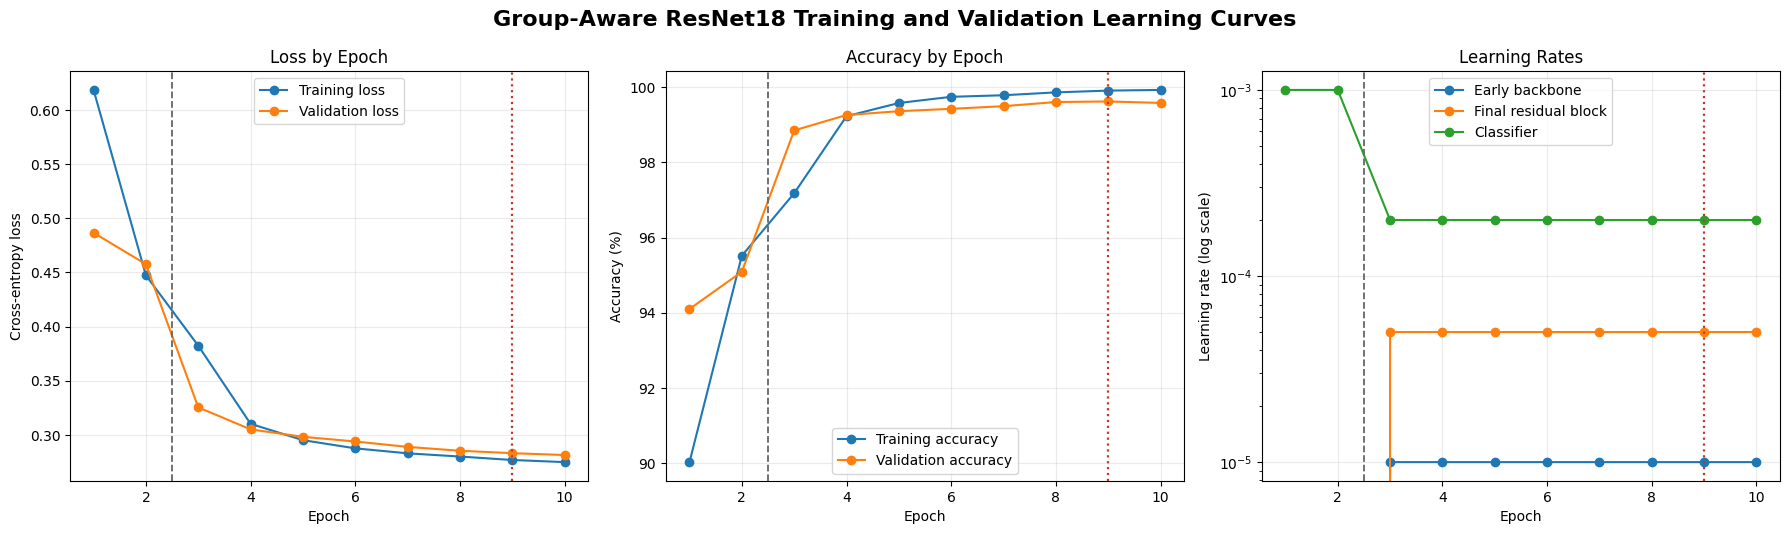

,epoch,stage,stage_epoch,early_backbone_lr,final_block_lr,classifier_lr,training_loss,training_accuracy,validation_loss,validation_accuracy,accuracy_gap,epoch_seconds,total_minutes
0,1,classifier_only,1,0.0,0.0,0.0010,0.6186,0.9003,0.4867,0.9410,-0.0407,1544.4407,25.7407
1,2,classifier_only,2,0.0,0.0,0.0010,0.4473,0.9552,0.4577,0.9509,0.0043,226.7995,29.5219
2,3,full_fine_tuning,1,0.0,0.0,0.0002,0.3824,0.9718,0.3254,0.9885,-0.0167,246.6231,33.6335
3,4,full_fine_tuning,2,0.0,0.0,0.0002,0.3102,0.9923,0.3050,0.9926,-0.0003,237.8603,37.5990
4,5,full_fine_tuning,3,0.0,0.0,0.0002,0.2951,0.9958,0.2982,0.9936,0.0022,238.8656,41.5813
5,6,full_fine_tuning,4,0.0,0.0,0.0002,0.2875,0.9975,0.2939,0.9943,0.0032,235.4632,45.5070
6,7,full_fine_tuning,5,0.0,0.0,0.0002,0.2829,0.9979,0.2889,0.9950,0.0029,236.0003,49.4415
7,8,full_fine_tuning,6,0.0,0.0,0.0002,0.2800,0.9986,0.2853,0.9961,0.0026,237.2830,53.3974
8,9,full_fine_tuning,7,0.0,0.0,0.0002,0.2768,0.9991,0.2831,0.9962,0.0029,239.2419,57.3859
9,10,full_fine_tuning,8,0.0,0.0,0.0002,0.2748,0.9993,0.2814,0.9958,0.0035,238.3378,61.3594


Best history epoch: 9
Learning curves: /kaggle/working/outputs/figures/figure_27_group_aware_resnet18_learning_curves.png


In [23]:
# Loads saved training history and plots accuracy loss and learning rates
saved_training_history = None

if TRAINING_HISTORY_PATH.exists():
    saved_training_history = pd.read_csv(
        TRAINING_HISTORY_PATH
    )

    best_epoch_row = saved_training_history.loc[
        saved_training_history[
            "validation_accuracy"
        ].idxmax()
    ]
    best_epoch = int(best_epoch_row["epoch"])

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 5.4),
    )

    axes[0].plot(
        saved_training_history["epoch"],
        saved_training_history["training_loss"],
        marker="o",
        label="Training loss",
    )
    axes[0].plot(
        saved_training_history["epoch"],
        saved_training_history["validation_loss"],
        marker="o",
        label="Validation loss",
    )
    axes[0].set_title("Loss by Epoch")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")
    axes[0].legend()

    axes[1].plot(
        saved_training_history["epoch"],
        saved_training_history["training_accuracy"] * 100,
        marker="o",
        label="Training accuracy",
    )
    axes[1].plot(
        saved_training_history["epoch"],
        saved_training_history["validation_accuracy"] * 100,
        marker="o",
        label="Validation accuracy",
    )
    axes[1].set_title("Accuracy by Epoch")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy (%)")
    axes[1].legend()

    for column, label in [
        ("early_backbone_lr", "Early backbone"),
        ("final_block_lr", "Final residual block"),
        ("classifier_lr", "Classifier"),
    ]:
        axes[2].plot(
            saved_training_history["epoch"],
            saved_training_history[column],
            marker="o",
            label=label,
        )
    axes[2].set_yscale("log")
    axes[2].set_title("Learning Rates")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Learning rate (log scale)")
    axes[2].legend()

    for axis in axes:
        axis.axvline(
            HEAD_ONLY_EPOCHS + 0.5,
            color="#666666",
            linestyle="--",
            linewidth=1.3,
            label="Fine-tuning begins",
        )
        axis.axvline(
            best_epoch,
            color="#C0392B",
            linestyle=":",
            linewidth=1.6,
        )
        axis.grid(alpha=0.25)

    fig.suptitle(
        "Group-Aware ResNet18 Training and Validation Learning Curves",
        fontsize=16,
        weight="bold",
    )
    fig.tight_layout()
    # Saves the figure so it can be included in the report
    fig.savefig(
        LEARNING_CURVES_PATH,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

    display(saved_training_history.round(4))
    print("Best history epoch:", best_epoch)
    print("Learning curves:", LEARNING_CURVES_PATH)
else:
    print("Training history is not available yet.")

## 24. Reload and Verify the Best Checkpoint

The best checkpoint is loaded into a fresh standard ResNet18 and evaluated on all 12,732 validation images. This confirms that the saved file is usable and that its accuracy is reproducible.

In [24]:
# Reloads the best checkpoint and checks it on every validation image
best_model_validation = None
training_summary = None

if BEST_MODEL_PATH.exists() and TRAINING_HISTORY_PATH.exists():
    # Reads the saved checkpoint so training does not need to be repeated
    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False,
    )

    best_model = models.resnet18(weights=None)
    best_model.fc = nn.Linear(
        best_model.fc.in_features,
        NUMBER_OF_CLASSES,
    )
    # Copies the saved weights into the matching model architecture
    best_model.load_state_dict(
        checkpoint["model_state_dict"]
    )
    best_model = best_model.to(DEVICE)

    if DEVICE.type == "cuda":
        best_model = best_model.to(
            memory_format=torch.channels_last
        )

    verification_loss = nn.CrossEntropyLoss(
        label_smoothing=LABEL_SMOOTHING
    )
    best_model_validation = validate_one_epoch(
        best_model,
        validation_loader,
        verification_loss,
        DEVICE,
    )

    saved_training_history = pd.read_csv(
        TRAINING_HISTORY_PATH
    )
    best_history_row = saved_training_history.loc[
        saved_training_history[
            "validation_accuracy"
        ].idxmax()
    ]

    if training_run_information is not None:
        stop_reason = training_run_information["stop_reason"]
        total_training_minutes = training_run_information[
            "total_training_minutes"
        ]
    elif TRAINING_SUMMARY_PATH.exists():
        with open(TRAINING_SUMMARY_PATH) as summary_file:
            previous_summary = json.load(summary_file)
        stop_reason = previous_summary["stop_reason"]
        total_training_minutes = previous_summary[
            "total_training_minutes"
        ]
    else:
        stop_reason = "recorded_run"
        total_training_minutes = float(
            saved_training_history.iloc[-1]["total_minutes"]
        )

    training_summary = {
        "experiment": "group_aware_baseline",
        "split_strategy": (
            "stratified connected perceptual groups"
        ),
        "original_validation_accuracy": 0.9965441407477222,
        "epochs_completed": int(len(saved_training_history)),
        "best_epoch": int(best_history_row["epoch"]),
        "best_stage": str(best_history_row["stage"]),
        "best_validation_loss": float(
            best_history_row["validation_loss"]
        ),
        "best_validation_accuracy": float(
            best_history_row["validation_accuracy"]
        ),
        "training_accuracy_at_best_epoch": float(
            best_history_row["training_accuracy"]
        ),
        "accuracy_gap_at_best_epoch": float(
            best_history_row["accuracy_gap"]
        ),
        "verified_validation_loss": float(
            best_model_validation["loss"]
        ),
        "verified_validation_accuracy": float(
            best_model_validation["accuracy"]
        ),
        "validation_images": int(
            best_model_validation["images"]
        ),
        "total_training_minutes": float(
            total_training_minutes
        ),
        "stop_reason": stop_reason,
        "pretrained_weight_source": checkpoint.get(
            "pretrained_weight_source",
            PRETRAINED_WEIGHT_SOURCE,
        ),
    }

    with open(TRAINING_SUMMARY_PATH, "w") as summary_file:
        json.dump(training_summary, summary_file, indent=4)

    display(pd.DataFrame([training_summary]).round(4))
    print("Training summary:", TRAINING_SUMMARY_PATH)
else:
    print("The trained checkpoint and history are pending.")

,experiment,split_strategy,original_validation_accuracy,epochs_completed,best_epoch,best_stage,best_validation_loss,best_validation_accuracy,training_accuracy_at_best_epoch,accuracy_gap_at_best_epoch,verified_validation_loss,verified_validation_accuracy,validation_images,total_training_minutes,stop_reason,pretrained_weight_source
0,group_aware_baseline,stratified connected perceptual groups,0.9965,10,9,full_fine_tuning,0.2831,0.9962,0.9991,0.0029,0.2831,0.9962,12732,61.3594,maximum_epochs,attached Kaggle input: /kaggle/input/datasets/...


Training summary: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_training_summary.json


## 25. Create Evidence for Overfitting or Underfitting

The report should interpret the complete curves rather than relying on one number. The table records the best and final results, the accuracy gap, and the minimum validation loss needed for that discussion.

In [25]:
# Summarises training behaviour and the training validation accuracy gap
behaviour_evidence = None

if saved_training_history is not None:
    best_epoch_row = saved_training_history.loc[
        saved_training_history[
            "validation_accuracy"
        ].idxmax()
    ]
    final_epoch_row = saved_training_history.iloc[-1]

    behaviour_evidence = pd.DataFrame(
        {
            "measure": [
                "Best validation epoch",
                "Best training stage",
                "Training accuracy at best epoch",
                "Validation accuracy at best epoch",
                "Accuracy gap at best epoch",
                "Validation loss at best epoch",
                "Lowest validation loss",
                "Final training accuracy",
                "Final validation accuracy",
                "Final validation loss",
                "Completed epochs",
                "Total training minutes",
                "Stopping reason",
            ],
            "value": [
                int(best_epoch_row["epoch"]),
                best_epoch_row["stage"],
                best_epoch_row["training_accuracy"],
                best_epoch_row["validation_accuracy"],
                best_epoch_row["accuracy_gap"],
                best_epoch_row["validation_loss"],
                saved_training_history[
                    "validation_loss"
                ].min(),
                final_epoch_row["training_accuracy"],
                final_epoch_row["validation_accuracy"],
                final_epoch_row["validation_loss"],
                len(saved_training_history),
                final_epoch_row["total_minutes"],
                (
                    training_summary["stop_reason"]
                    if training_summary is not None
                    else "pending"
                ),
            ],
        }
    )
    # Saves the table as a CSV file for later notebooks or report evidence
    behaviour_evidence.to_csv(
        BEHAVIOUR_EVIDENCE_PATH,
        index=False,
    )

    display(behaviour_evidence)
    print("Behaviour evidence:", BEHAVIOUR_EVIDENCE_PATH)
else:
    print("Model-behaviour evidence is pending training.")

,measure,value
0,Best validation epoch,9
1,Best training stage,full_fine_tuning
2,Training accuracy at best epoch,0.999116
3,Validation accuracy at best epoch,0.99623
4,Accuracy gap at best epoch,0.002886
5,Validation loss at best epoch,0.283086
6,Lowest validation loss,0.281364
7,Final training accuracy,0.999293
8,Final validation accuracy,0.995837
9,Final validation loss,0.281364


Behaviour evidence: /kaggle/working/outputs/models/group_aware_baseline/group_aware_resnet18_behaviour_evidence.csv


## 26. Run Final Training and Evidence Checks

When training artifacts exist, every required result is checked. Preparation mode reports that training remains pending rather than creating false results.

In [26]:
# Checks that model histories checkpoints and evidence are complete
required_history_columns = {
    "epoch",
    "stage",
    "stage_epoch",
    "early_backbone_lr",
    "final_block_lr",
    "classifier_lr",
    "training_loss",
    "training_accuracy",
    "validation_loss",
    "validation_accuracy",
    "accuracy_gap",
    "epoch_seconds",
    "total_minutes",
}

if saved_training_history is None:
    NOTEBOOK_9_STATUS = (
        "Pending - training code prepared but not executed"
    )
    print("Notebook 9 status:", NOTEBOOK_9_STATUS)
else:
    loss_values_are_finite = np.isfinite(
        saved_training_history[
            ["training_loss", "validation_loss"]
        ].to_numpy()
    ).all()
    accuracy_values_are_valid = (
        saved_training_history[
            ["training_accuracy", "validation_accuracy"]
        ]
        .apply(lambda column: column.between(0, 1).all())
        .all()
    )

    final_checks = pd.DataFrame(
        {
            "check": [
                "At least one epoch completed",
                "All required history columns exist",
                "All loss values are finite",
                "All accuracy values are between 0 and 1",
                "Classifier-only stage completed",
                "Fine-tuning stage started",
                "Best checkpoint exists",
                "Learning-curves figure exists",
                "Training summary exists",
                "Behaviour evidence exists",
                "Best model checked on all validation images",
                "Training completed within two hours",
                "Checkpoint records eight classes",
            ],
            "result": [
                len(saved_training_history) >= 1,
                required_history_columns.issubset(
                    saved_training_history.columns
                ),
                loss_values_are_finite,
                accuracy_values_are_valid,
                (
                    saved_training_history["stage"]
                    == "classifier_only"
                ).any(),
                (
                    saved_training_history["stage"]
                    == "full_fine_tuning"
                ).any(),
                BEST_MODEL_PATH.exists(),
                LEARNING_CURVES_PATH.exists(),
                TRAINING_SUMMARY_PATH.exists(),
                BEHAVIOUR_EVIDENCE_PATH.exists(),
                best_model_validation is not None
                and best_model_validation["images"]
                == len(validation_dataset),
                saved_training_history.iloc[-1][
                    "total_minutes"
                ] <= ASSIGNMENT_TIME_LIMIT_MINUTES,
                list(checkpoint["class_names"]) == CLASS_NAMES,
            ],
            "expected": [True] * 13,
        }
    )

    display(final_checks)
    assert final_checks["result"].all()

    NOTEBOOK_9_STATUS = "Completed and verified"
    print("Notebook 9 status:", NOTEBOOK_9_STATUS)

,check,result,expected
0,At least one epoch completed,True,True
1,All required history columns exist,True,True
2,All loss values are finite,True,True
3,All accuracy values are between 0 and 1,True,True
4,Classifier-only stage completed,True,True
5,Fine-tuning stage started,True,True
6,Best checkpoint exists,True,True
7,Learning-curves figure exists,True,True
8,Training summary exists,True,True
9,Behaviour evidence exists,True,True


Notebook 9 status: Completed and verified


## 27. Package the Kaggle Results

After training, this cell creates one ZIP file containing the checkpoint and every essential report artifact. Download the ZIP before closing the Kaggle session.

In [27]:
# Packages the saved model and report evidence for download
if BEST_MODEL_PATH.exists() and TRAINING_HISTORY_PATH.exists():
    result_files = [
        BEST_MODEL_PATH,
        TRAINING_HISTORY_PATH,
        TRAINING_SUMMARY_PATH,
        PIPELINE_CONFIG_PATH,
        ARCHITECTURE_TABLE_PATH,
        HYPERPARAMETER_PATH,
        PARAMETER_SUMMARY_PATH,
        TRAINING_STAGES_PATH,
        GENERALISATION_PATH,
        PIPELINE_CHECKS_PATH,
        BEHAVIOUR_EVIDENCE_PATH,
        ARCHITECTURE_FIGURE_PATH,
        LEARNING_CURVES_PATH,
    ]

    missing_result_files = [
        path for path in result_files if not path.exists()
    ]
    if missing_result_files:
        raise FileNotFoundError(
            "Missing result files:\n"
            + "\n".join(
                str(path) for path in missing_result_files
            )
        )

    archive_path = (
        PROJECT_ROOT / "group_aware_resnet18_baseline_results.zip"
    )

    with ZipFile(
        archive_path,
        "w",
        ZIP_DEFLATED,
    ) as archive:
        for result_file in result_files:
            archive.write(
                result_file,
                arcname=result_file.relative_to(PROJECT_ROOT),
            )

    print("Saved:", archive_path)
    print(
        "Archive size:",
        f"{archive_path.stat().st_size / 1_000_000:.1f} MB",
    )
    display(FileLink(str(archive_path)))
else:
    print("The result archive will be created after training.")

Saved: /kaggle/working/group_aware_resnet18_baseline_results.zip
Archive size: 42.0 MB


/kaggle/working/group_aware_resnet18_baseline_results.zip

## 28. Generate the Final Notebook Conclusion

After training, this cell produces a concise result summary directly from the saved evidence. The full comparison with the custom CNN will be completed in Notebook 5.

In [28]:
# Displays a conclusion based on the saved training results
if training_summary is not None:
    accuracy_percent = training_summary["best_validation_accuracy"] * 100
    original_percent = 0.9965441407477222 * 100
    difference_points = accuracy_percent - original_percent
    gap_points = training_summary["accuracy_gap_at_best_epoch"] * 100

    display(
        Markdown(
            f"""
# Notebook 9 Conclusion

The unchanged pretrained ResNet18 completed **{training_summary['epochs_completed']} epochs** on the group-aware split and stopped because of **{training_summary['stop_reason']}**. Its best checkpoint was produced during **{training_summary['best_stage']}** at epoch **{training_summary['best_epoch']}**.

Group-aware validation accuracy was **{accuracy_percent:.2f}%**, compared with **{original_percent:.2f}%** on the original split—a difference of **{difference_points:+.2f} percentage points**. The training-validation gap at the best epoch was **{gap_points:.2f} percentage points**.

The checkpoint was reloaded and evaluated on all **{training_summary['validation_images']:,} group-aware validation images**. This experiment changes only split membership, so the comparison estimates how much the original validation result depended on detected near-duplicate relationships.
"""
        )
    )
else:
    display(
        Markdown(
            """
# Notebook 9 Conclusion - Pending Training

The unchanged ResNet18 training pipeline is prepared for the group-aware split. Run the notebook on Kaggle with training enabled to obtain the controlled baseline.
"""
        )
    )


# Notebook 9 Conclusion

The unchanged pretrained ResNet18 completed **10 epochs** on the group-aware split and stopped because of **maximum_epochs**. Its best checkpoint was produced during **full_fine_tuning** at epoch **9**.

Group-aware validation accuracy was **99.62%**, compared with **99.65%** on the original split—a difference of **-0.03 percentage points**. The training-validation gap at the best epoch was **0.29 percentage points**.

The checkpoint was reloaded and evaluated on all **12,732 group-aware validation images**. This experiment changes only split membership, so the comparison estimates how much the original validation result depended on detected near-duplicate relationships.
